# 09. Xử lý mất cân bằng lớp (Phase 9 / Experiment C)

Screening các kỹ thuật xử lý mất cân bằng lớp trên **backbone C** = `fusion_concat_frozen_reg` (PhoBERT + CLIP đóng băng, concat có regularize), theo `docs/empirical_analysis_plan.md` mục 8. Notebook này bổ sung **B2, B4, B5** (task 9.3, 9.4) vào cùng plan với B0, B1, B3 (task 9.1, 9.2) đã chạy ở notebook `phase-9-task-1-2`, rồi so sánh cả 6 cột.

| ID | Kỹ thuật | Config | Run | Task |
|---|---|---|---|---|
| B0 | CE, lấy mẫu tự nhiên (đối chứng) | `fusion_concat_frozen_reg` | `emp_c_ce_s42` | 9.1, 9.2 |
| B1 | CE + class weight `sqrt_inverse` | `fusion_concat_frozen_reg_cw` | `emp_c_cw_s42` | 9.1 |
| B2 | CE + oversampling √ nghịch đảo tần suất | `fusion_concat_frozen_reg_oversample` | `emp_c_oversample_s42` | **9.3** |
| B3 | Focal loss γ=2, không class weight | `fusion_concat_frozen_reg_focal` | `emp_c_focal_s42` | 9.2 |
| B4 | Augmentation caption lớp hiếm + CE | `fusion_concat_frozen_reg_aug` | `emp_c_aug_s42` | **9.4** |
| B5 | Augmentation + class weight `sqrt_inverse` | `fusion_concat_frozen_reg_aug_cw` | `emp_c_aug_cw_s42` | **9.4** |

**Giao thức chung (giống 9.1, 9.2):** split chính thức (train 10.805 gốc, chưa lọc nhiễu; val = public test 1.413), seed 42, chọn checkpoint theo val macro-F1 bỏ `text-sarcasm` (val chỉ có 1 mẫu), không chấm private test (`train.eval_test=false`). Mọi kỹ thuật rút **cùng số mẫu mỗi epoch** như B0 (10.805), nên cùng số bước cập nhật; bản augmentation không làm epoch dài thêm.

- **B2:** mẫu lớp c được rút với trọng số n_c^-0.5, nên tỉ lệ lớp trong epoch ∝ √n_c. Nhẹ tay hơn cân bằng hẳn (sampler `weighted` cũ, lặp `text-sarcasm` khoảng 35 lần mỗi epoch).
- **B4/B5:** back-translation vi → en → vi (`vinai-translate`) caption của `text-sarcasm` và `image-sarcasm` trong train, ảnh giữ nguyên. Mỗi mẫu gốc sinh 2 bản, lọc tự động bằng luật, train dùng tối đa 1 bản được giữ. File duyệt `augmentation_review.csv` để người kiểm tra lại nghĩa và nhãn.

**Input cần Add:** `phuclkz/vimmsd-private-dataset`, `vtnmai/vimmsd-data-preprocessed` (cache caption đã tiền xử lý; bản nào cũng được nếu `pipeline_key` khớp code, cell kiểm tra dữ liệu sẽ báo). Nên add thêm **output notebook `phuclkz/phase-9-task-1-2`** để dùng lại B0, B1, B3 (không có thì notebook chạy lại cả 3, thêm khoảng 1 giờ).
**Settings:** GPU T4 x2, **Internet on** (tải model dịch và cài Java).

In [1]:
# === Cell bootstrap (giống nhau ở mọi notebook, xem CODEBASE.md mục 6) ===
import os, subprocess, sys
from pathlib import Path

REPO = "github.com/meo225/Multimodal_Sarcasm_Detection.git"
REF = "feat/phase9-oversampling-augment"               # branch của mình, hoặc 1 commit hash để tái lặp kết quả (ghi hash vào reports/results.md)
CODE_DIR = "/tmp/IE403"    # clone ra ngoài /kaggle/working để token không bị lưu vào output


def get_github_token():
    """Token cho repo private; repo public thì không cần tạo secret."""
    try:
        if os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret("GITHUB_TOKEN")
        from google.colab import userdata
        return userdata.get("GITHUB_TOKEN")
    except Exception:
        return None


ON_CLOUD = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE")) or "COLAB_RELEASE_TAG" in os.environ
if ON_CLOUD:
    if "COLAB_RELEASE_TAG" in os.environ and not os.environ.get("KAGGLE_KERNEL_RUN_TYPE"):  # ảnh Kaggle dựng từ ảnh Colab nên cũng có biến này
        from google.colab import drive
        drive.mount("/content/drive")
    token = get_github_token()
    url = f"https://{token}@{REPO}" if token else f"https://{REPO}"
    subprocess.run(["rm", "-rf", CODE_DIR])
    subprocess.run(["git", "clone", "-q", url, CODE_DIR], check=True)
    subprocess.run(["git", "-C", CODE_DIR, "checkout", "-q", REF], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE_DIR}/requirements-kaggle.txt"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", CODE_DIR], check=True)
    if CODE_DIR + "/src" not in sys.path:
        sys.path.insert(0, CODE_DIR + "/src")  # kernel đang chạy chưa thấy package vừa cài -e
    os.chdir(CODE_DIR)
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # local: chạy từ gốc repo (đã `pip install -e .` một lần)

print("cwd:", os.getcwd())
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("code commit:", commit or "unknown")

cwd: /tmp/IE403
code commit: 1e86ff3


In [2]:
# VnCoreNLP (tách từ cho PhoBERT) cần Java để tiền xử lý caption mới sinh ở B4/B5
if subprocess.run(["java", "-version"], capture_output=True).returncode != 0:
    subprocess.run("apt-get -qq update && apt-get -qq install -y default-jre-headless > /dev/null", shell=True, check=True)
print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])

RUN_TESTS = True
if RUN_TESTS:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
    result = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-x", "-p", "no:cacheprovider"],
                            capture_output=True, text=True)
    print(result.stdout[-3000:], result.stderr[-2000:])
    if result.returncode != 0:
        raise RuntimeError("pytest fail, xem output phía trên trước khi train")

openjdk version "21.0.12.1" 2026-08-18
.....................................................s.................. [ 31%]
........................................................................ [ 63%]
........................................................................ [ 95%]
...........                                                              [100%]
=============================== warnings summary ===============================
tests/test_stacking.py::test_stacking_learns_which_model_to_trust
  /usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
    opt_res = optimize.minimize(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
226 passed, 1 skipped, 1 warning in 41.05s
 


In [3]:
import json
import logging
import re
import shutil
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vimmsd.utils.config import load_config
from vimmsd.utils.experiments import expand_runs, load_plan, run_output_dir

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", force=True)
logging.getLogger("httpx").setLevel(logging.WARNING)
pd.set_option("display.max_colwidth", 120)

PLAN = "configs/experiments/empirical_imbalance_screen.yaml"
# Output notebook 9.1/9.2 (Add Input). None = tự tìm emp_c_*_s42 trong /kaggle/input; không thấy thì chạy lại B0/B1/B3.
PREVIOUS_OUTPUT = None
# File augmentation_review.csv đã điền cột review (accept | reject), Add Input rồi điền đường dẫn. None = chỉ lọc tự động.
REVIEWED_CSV = None

METHODS = {  # ID -> (tên run, mô tả ngắn)
    "B0": ("emp_c_ce", "CE (đối chứng)"),
    "B1": ("emp_c_cw", "CE + class weight"),
    "B2": ("emp_c_oversample", "Oversampling √"),
    "B3": ("emp_c_focal", "Focal γ=2"),
    "B4": ("emp_c_aug", "Augmentation"),
    "B5": ("emp_c_aug_cw", "Augmentation + class weight"),
}
plan = load_plan(PLAN)
specs = {s.group: s for s in expand_runs(plan)}
OUT = run_output_dir(next(iter(specs.values()))).parent
cfg = load_config(specs["emp_c_ce"].config, specs["emp_c_ce"].overrides)
LABELS = list(cfg.data.labels)
RARE = "text-sarcasm"
print("output:", OUT)

output: /kaggle/working/outputs


## 1. Kiểm tra dữ liệu

Dùng **bộ train gốc** (`phuclkz/vimmsd-private-dataset`, 10.805 mẫu), giống 9.1 và 9.2. Bản lọc nhiễu của Phase "Lọc data nhiễu" chỉ cấu hình trên GPU server (`paths.server`), bớt 25 mẫu (10.805 → 10.780) và chưa cho thấy cải thiện ở text-only / image-only (`reports/results.md`, plan `denoise_compare`), nên không dùng ở đây để giữ so sánh được với các phase trước.

2026-11-14 11:08:44,103 INFO copy /kaggle/input/datasets/vtnmai/vimmsd-data-preprocessed/text_preprocessed.json -> /kaggle/working/cache/text_preprocessed.json


text_preprocessed.json: pipeline_key=2c3852f6, code hiện tại=2c3852f6


,train,val,train (%)
not-sarcasm,6062,442,56.10
text-sarcasm,77,1,0.71
image-sarcasm,442,28,4.09
multi-sarcasm,4224,942,39.09


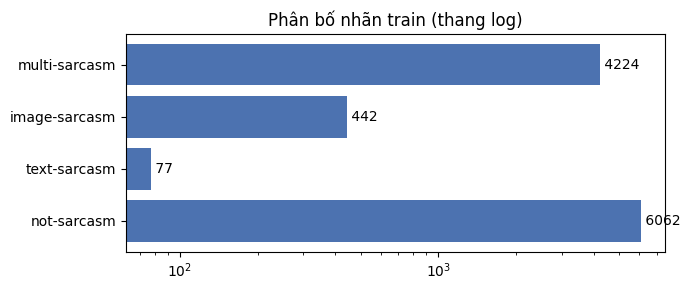

In [4]:
from vimmsd.data.dataset import load_all_records, stage_preprocessed_cache

data_dir = Path(cfg.paths.data_dir)
if not (data_dir / cfg.data.train_json).exists():
    raise FileNotFoundError(f"không thấy {data_dir / cfg.data.train_json}: Add Input phuclkz/vimmsd-private-dataset")
from vimmsd.data.preprocessing import TextPreprocessor

expected_key = TextPreprocessor.from_config(cfg.data.text).pipeline_key()
for path in stage_preprocessed_cache(cfg):
    key = json.loads(path.read_text(encoding="utf-8")).get("meta", {}).get("pipeline_key")
    print(f"{path.name}: pipeline_key={key}, code hiện tại={expected_key}")
    if key != expected_key:
        raise ValueError(f"{path.name} tạo bởi pipeline khác: train sẽ tiền xử lý lại toàn bộ caption. "
                         "Add Input đúng dataset cache (vtnmai/vimmsd-data-preprocessed) rồi chạy lại")

splits = load_all_records(cfg)
counts = pd.DataFrame({split: Counter(LABELS[r["label"]] for r in splits[split]) for split in ("train", "val")}).reindex(LABELS)
counts["train (%)"] = (100 * counts["train"] / counts["train"].sum()).round(2)
display(counts)
assert (len(splits["train"]), len(splits["val"])) == (10805, 1413), "số mẫu không khớp split chính thức"

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(LABELS, counts["train"], color="#4c72b0")
ax.set_xscale("log")
for y, v in enumerate(counts["train"]):
    ax.text(v, y, f" {v}", va="center")
ax.set_title("Phân bố nhãn train (thang log)")
plt.tight_layout(); plt.show()

## 2. B2: oversampling √ nghịch đảo tần suất

Số lần mỗi lớp được rút trong một epoch (kỳ vọng), với cùng 10.805 lượt rút. `weighted (power 1)` là sampler cũ cân bằng hẳn các lớp, chỉ để tham chiếu, không chạy.

lượt rút / epoch                                                \
sampler            random (B0) weighted power 1 (tham chiếu) weighted √ (B2)   
lớp                                                                            
not-sarcasm             6062.0                        2701.3          4872.7   
text-sarcasm              77.0                        2701.3           549.2   
image-sarcasm            442.0                        2701.3          1315.7   
multi-sarcasm           4224.0                        2701.3          4067.4   

              lặp mỗi mẫu / epoch                                \
sampler               random (B0) weighted power 1 (tham chiếu)   
lớp                                                               
not-sarcasm                   1.0                           0.4   
text-sarcasm                  1.0                          35.1   
image-sarcasm                 1.0                           6.1   
multi-sarcasm                 1.0                           0.6   

                               
sampler       weighted √ (B2)  
lớp                            
not-sarcasm               0.8  
text-sarcasm              7.1  
image-sarcasm             3.0  
multi-sarcasm             1.0

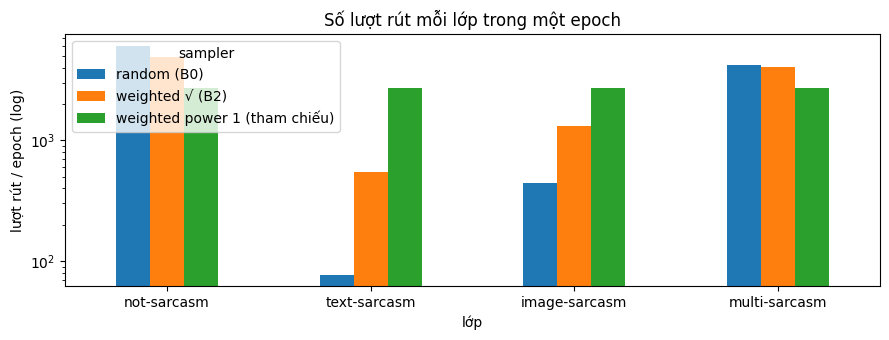

In [5]:
from vimmsd.data.dataset import ViMMSDDataset, build_train_sampler, sampling_summary

train_ds = ViMMSDDataset(splits["train"], load_image=False)
modes = {"random (B0)": ("random", 1.0), "weighted √ (B2)": ("weighted", 0.5), "weighted power 1 (tham chiếu)": ("weighted", 1.0)}
rows = []
for name, (mode, power) in modes.items():
    summary = sampling_summary(train_ds, LABELS, build_train_sampler(train_ds, len(LABELS), mode, power, seed=42))
    for label, s in summary["classes"].items():
        rows.append({"sampler": name, "lớp": label, "lượt rút / epoch": s["draws_per_epoch"],
                     "lặp mỗi mẫu / epoch": s["draws_per_epoch"] / s["samples"],
                     "mẫu khác nhau thấy / epoch": s["unique_seen_per_epoch"]})
draws = pd.DataFrame(rows)
display(draws.pivot(index="lớp", columns="sampler", values=["lượt rút / epoch", "lặp mỗi mẫu / epoch"]).reindex(LABELS).round(1))

pivot = draws.pivot(index="lớp", columns="sampler", values="lượt rút / epoch").reindex(LABELS)[list(modes)]
ax = pivot.plot.bar(figsize=(9, 3.5), rot=0, logy=True)
ax.set_ylabel("lượt rút / epoch (log)")
ax.set_title("Số lượt rút mỗi lớp trong một epoch")
plt.tight_layout(); plt.show()

## 3. B4/B5: sinh và lọc augmentation

`scripts/augment_captions.py`: back-translation caption của `text-sarcasm` và `image-sarcasm` (2 bản mỗi mẫu gốc), nối lại emoji bị mất, rồi lọc tự động. Loại khi: caption gốc dưới 3 từ hoặc trên 150 từ (bản dịch bị cắt), gần trùng caption gốc (giống > 0,9), độ dài lệch ngoài 0,6–1,6 lần, đổi con số, thêm từ chỉ nhãn ("mỉa mai", "sarcasm"...), lặp từ, hoặc trùng một caption khác trong train. Mỗi mẫu gốc giữ tối đa **1** bản, ưu tiên bản giống caption gốc nhất (ít sai nghĩa nhất).

> Lần chạy lưu trong notebook này (commit `1e86ff3`) dùng luật cũ: chưa lọc caption gốc quá ngắn/quá dài, độ giống của caption dài bị tính sai (difflib autojunk) và ưu tiên bản *khác* caption gốc nhất. Đã sửa ở commit sau; muốn B4/B5 dùng luật mới thì chạy lại 2 run này.

Lọc tự động không kiểm được nghĩa, ý mỉa mai hay nhãn modality. Muốn duyệt tay: tải `augmentation_review.csv` ở Output, điền cột `review` = `accept` / `reject`, Add Input file đó, đặt `REVIEWED_CSV` rồi chạy lại từ cell này (B4/B5 sẽ train lại với bản đã duyệt nếu xoá output cũ của chúng).

In [6]:
aug_cfg = load_config(specs["emp_c_aug"].config, specs["emp_c_aug"].overrides)
cmd = [sys.executable, "scripts/augment_captions.py", "--config", str(specs["emp_c_aug"].config), "--override", *specs["emp_c_aug"].overrides]
if REVIEWED_CSV:
    cmd += ["--import-review", REVIEWED_CSV]
subprocess.run(cmd, check=True)

2026-11-14 11:08:50,190 INFO dùng cache có sẵn /kaggle/working/cache/text_preprocessed.json
2026-11-14 11:08:50,495 INFO 519 mẫu gốc {'image-sarcasm': 442, 'text-sarcasm': 77}, mỗi mẫu 2 bản
2026-11-14 11:08:54,390 INFO HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-11-14 11:08:54,439 INFO HTTP Request: GET https://huggingface.co/api/models/vinai/vinai-translate-vi2en-v2 "HTTP/1.1 200 OK"
2026-11-14 11:08:54,483 INFO HTTP Request: HEAD https://huggingface.co/vinai/vinai-translate-vi2en-v2/resolve/ae7baa85da07dbe8e23ac26a9f5ef560c17e2138/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-14 11:08:54,484 WARNING Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-14 11:08:54,526 INFO HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/vinai/vinai-translate-vi2en-v2/ae7baa85da07dbe8e23ac26a9f5ef560c17e2138/config.json?%2Fvinai%2Fvinai-transla

2026-11-14 11:25:25 INFO  WordSegmenter:24 - Loading Word Segmentation model


2026-11-14 11:25:27,727 INFO manifest /kaggle/working/cache/augmentation_manifest.jsonl | file duyệt /kaggle/working/cache/augmentation_review.csv
2026-11-14 11:25:27,729 INFO image-sarcasm: 884 bản, lọc tự động giữ 477, người đã duyệt 0, dùng để train 279
2026-11-14 11:25:27,729 INFO text-sarcasm: 154 bản, lọc tự động giữ 87, người đã duyệt 0, dùng để train 47


CompletedProcess(args=['/usr/bin/python3', 'scripts/augment_captions.py', '--config', '/tmp/IE403/configs/fusion_concat_frozen_reg_aug.yaml', '--override', 'data.split_seed=42', 'train.eval_test=false', 'train.select_exclude_labels=[text-sarcasm]', 'seed=42', 'name=emp_c_aug_s42'], returncode=0)

,mẫu_gốc,bản_sinh,lọc_tự_động_giữ,người_đã_duyệt,dùng_để_train,tỉ lệ mẫu gốc có bản dùng (%)
label,,,,,,
image-sarcasm,442,884,477,0,279,63.1
text-sarcasm,77,154,87,0,47,61.0


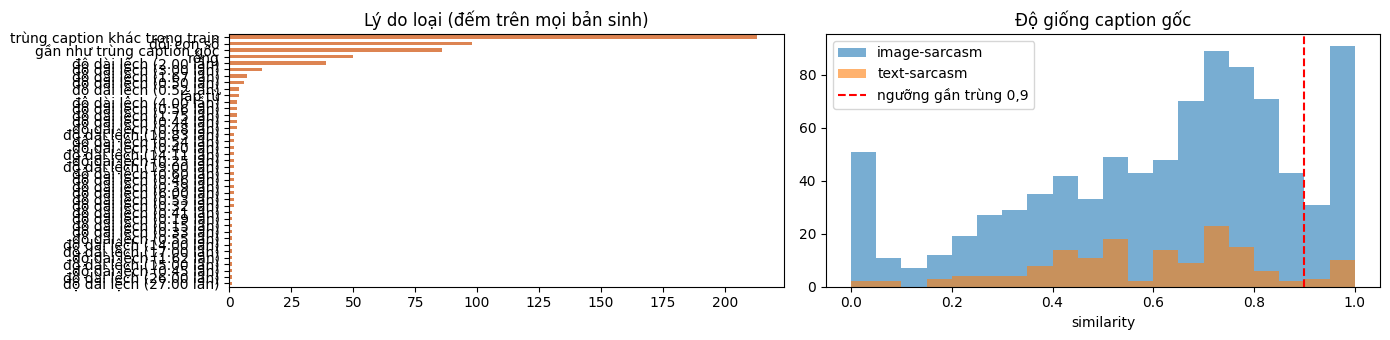

file duyệt: /kaggle/working/augmentation_review.csv


In [7]:
from vimmsd.data.augmentation import accepted_variants, read_manifest
from vimmsd.data.dataset import augment_manifest_path

manifest_path = augment_manifest_path(aug_cfg)
manifest = pd.DataFrame(read_manifest(manifest_path))
used = {(v[0]["parent_id"], v[0]["candidate"]) for v in accepted_variants(manifest.to_dict("records")).values()}
manifest["dùng để train"] = [(p, c) in used for p, c in zip(manifest["parent_id"], manifest["candidate"])]

per_class = manifest.groupby("label").agg(
    mẫu_gốc=("parent_id", "nunique"), bản_sinh=("caption", "size"),
    lọc_tự_động_giữ=("auto_verdict", lambda s: (s == "accept").sum()),
    người_đã_duyệt=("review", lambda s: s.notna().sum()), dùng_để_train=("dùng để train", "sum"))
per_class["tỉ lệ mẫu gốc có bản dùng (%)"] = (100 * per_class["dùng_để_train"] / per_class["mẫu_gốc"]).round(1)
display(per_class)

reasons = Counter(r for rs in manifest["auto_reasons"] for r in rs)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
pd.Series(reasons).sort_values().plot.barh(ax=axes[0], color="#dd8452")
axes[0].set_title("Lý do loại (đếm trên mọi bản sinh)")
for label, part in manifest.groupby("label"):
    axes[1].hist(part["similarity"], bins=20, range=(0, 1), alpha=0.6, label=label)
axes[1].axvline(0.9, color="red", linestyle="--", label="ngưỡng gần trùng 0,9")
axes[1].set_title("Độ giống caption gốc"); axes[1].set_xlabel("similarity"); axes[1].legend()
plt.tight_layout(); plt.show()

shutil.copy(manifest_path.with_name("augmentation_review.csv"), "/kaggle/working/augmentation_review.csv")
print("file duyệt: /kaggle/working/augmentation_review.csv")

In [8]:
# Ví dụ để nghiệm thu bằng mắt: caption gốc và bản được dùng, mỗi lớp 8 mẫu; rồi vài bản bị loại
for label in ("text-sarcasm", "image-sarcasm"):
    part = manifest[(manifest["label"] == label) & manifest["dùng để train"]]
    print(f"=== {label}: {len(part)} bản dùng để train")
    display(part.sample(min(8, len(part)), random_state=0)[["parent_id", "parent_caption", "caption", "similarity"]])
rejected = manifest[manifest["auto_verdict"] == "reject"]
print(f"=== bị loại: {len(rejected)} bản")
display(rejected.sample(min(8, len(rejected)), random_state=0)[["label", "parent_caption", "caption", "auto_reasons"]])

=== text-sarcasm: 47 bản dùng để train


,parent_id,parent_caption,caption,similarity
700,4964,Tại ở chung với Ông 5 nên được top 5. Biết z hồi đó t ở nhà ông 1 😒,Khi sống với ông 5 nên là top 5. Biết z sau đó t tại nhà của mình 1 😒,0.7231
790,5999,Chu Bin cũng mong khán giả đừng mang từ 'vãi Chu Bin' ra làm trò cười nữa,"Zhou Bin cũng mong rằng khán giả sẽ ngừng chế giễu từ ""Zhou Bin poop"".",0.6087
719,5102,Mot cai ket co hau\nmon.,Mot cai ket co hau mon (bằng tiếng Anh).,0.7458
54,521,Lưỡi không xương mà lại,Lưỡi không có xương.,0.7619
579,3740,Nhà ngọt\n-kem,Ngọt -cream Nhà,0.5385
161,942,Bảo sao mấy 🐕 ở quê hay chạy đuổi mình chả bao giờ vẫy đuôi\n-Kiến Know-,Tại sao những gã từ đất nước này không bao giờ vẫy đuôi theo tôi? 🐕,0.4427
986,9621,Nhậu là để VUI \nchứ ko phải để XUI\n#Heineken00 #Ken0Do #CamLai0Lo #VuiTiec0Lo #ChoiLe0Lo,"Uống cho vui, không phải cho XUI #Heineken00 #Ken0Do #CamLai0Lo #VuiTiec0Lo #ChoiLe0Lo",0.8272
727,5120,FERGIEEEEE TIMEEEEEEEEEEEEE !!!!!!\nVới những người thường xuyên theo dõi bóng đá thì chắc hẳn chúng ta không còn lạ...,"FERGIEEEEE TIMEEEEEEEEEE!!!!!! Đối với những người thường xuyên theo dõi bóng đá, chúng ta không xa lạ gì với khái n...",0.2942


=== image-sarcasm: 279 bản dùng để train


,parent_id,parent_caption,caption,similarity
824,7097,Ủa:))))\n#phetphaikhong,Sắt:)))) #phetphaikhong,0.8485
864,7817,"#VOZ_F33 - 2 con trai U50 nhà trưởng họ không chịu lấy vợ, cả làng sốt ruột\nhttps://voz.vn/.../2-con-trai-u50-nha-t...","#VOZ_F33 - 2 con trai U50 người đứng đầu họ từ chối kết hôn, cả làng nôn nóng https://voz.vn/.../2-con-trai-u50-nha-...",0.7750
938,8810,Gợi ý idea đăng bài cho người bí content\n#interpool,Đề xuất ý tưởng đăng cho nội dung người bí mật #interpool,0.6226
50,451,"Lê Bống được khen ngợi, làm biên tập viên truyền hình qua ống kính cam thường vẫn xinh","Le Bong được ca ngợi, là biên tập viên truyền hình thông qua ống kính màu cam thường vẫn còn đẹp",0.8333
192,1289,"Hãy tag một trưởng nhóm và một linh vật xuống đây nhưng không nói ai là trưởng nhóm, ai là linh vật, để chúng nó tự ...","Hãy gắn thẻ một nhà lãnh đạo và một linh vật ở đây nhưng đừng nói ai là nhà lãnh đạo, ai là linh vật, để họ có thể đ...",0.6733
896,8347,"#VOZ_F33 - Cô gái 22 tuổi xinh đẹp hẹn hò nam kỹ sư 31 tuổi, thu nhập 100 triệu đồng\nLink ở comment","#VOZ_F33 - Cô gái xinh đẹp 22 tuổi hẹn hò với nam kỹ sư 31 tuổi, thu nhập 100 triệu đồng Link in comment",0.8821
981,9571,#VOZ_F33 - Đặt tên Đôi Hậu sau sáp nhập xã Quỳnh Đôi và Quỳnh Hậu: Do xã nào cũng muốn giữ tên của mình\nhttps://voz...,#VOZ_F33 - Đặt tên Đôi Hậu sau khi sáp nhập xã Quỳnh Đôi và Quỳnh Hậu: Vì mỗi xã đều muốn giữ tên https://voz.vn/......,0.8912
637,4075,Mẹ này 🥲,Này mẹ 🥲,0.5000


=== bị loại: 474 bản


,label,parent_caption,caption,auto_reasons
205,image-sarcasm,"Tại sao bạn nên học tính nhẩm - tiếp tục phần 2 series ""Thanh xuân pểvt của Ivan"". Phần này dài gấp rưỡi phần 1 :v\n...","Tại sao bạn nên học để làm điều đó trong đầu của bạn - tiếp tục phần 2 của loạt bài ""Ivan của xe tăng mùa xuân"". Phầ...",[trùng caption khác trong train]
236,image-sarcasm,Ditcu nửa đêm nhận được tin nhắn này phải làm sao đây ae,Ditcu nửa đêm nhận được tin nhắn này phải làm gì ae,[gần như trùng caption gốc]
528,image-sarcasm,Đừng có nhờn mặt \n#NIVEAMEN #DETOXMUD #Bunkhoang #Dangmatphaimanh,Đừng nhờn #NIVEAMEN #DETOXMUD #Bunkhoang #Dangmatphaimanh,[gần như trùng caption gốc]
457,image-sarcasm,Sốc,Cú sốc,[độ dài lệch (2.00 lần)]
934,image-sarcasm,-The Deep\n#Interpool,-Sâu #Interpool,[trùng caption khác trong train]
871,image-sarcasm,-kem-\n#Interpool,-cream- #Interpool (Tiếng Việt),[độ dài lệch (2.00 lần)]
356,image-sarcasm,"HƯỚNG DẪN CH.ỐT VARIO MỘT TRĂM SÁU CHỤC\nHơn cả một chiếc xe, VARIO là Sonic của tay ga, là Dream của tuổi trẻ, là W...","Hơn cả một chiếc xe hơi, VARIO là Sonic của chiếc xe tay ga, Giấc mơ của tuổi trẻ, Người chiến thắng của tình yêu! Đ...",[đổi con số]
960,image-sarcasm,Never forget 😭\n#interpool,Đừng bao giờ quên #interpool 😭,[độ dài lệch (1.67 lần)]


## 4. Train

Run đã có `results_row.md` thì bỏ qua: B0, B1, B3 lấy từ output 9.1/9.2 nếu có. Hai GPU chạy song song, mỗi GPU một run (khoảng 30 phút mỗi run). Log từng run ở `outputs/<run>/run.log`.

In [9]:
if PREVIOUS_OUTPUT is None:
    hits = sorted(Path("/kaggle/input").rglob("emp_c_*_s42/results_row.md")) if Path("/kaggle/input").exists() else []
    PREVIOUS_OUTPUT = hits[0].parent.parent if hits else None
if PREVIOUS_OUTPUT and Path(PREVIOUS_OUTPUT).resolve() != OUT.resolve():
    for row_file in sorted(Path(PREVIOUS_OUTPUT).glob("emp_c_*/results_row.md")):
        if not (OUT / row_file.parent.name / "results_row.md").exists():
            shutil.copytree(row_file.parent, OUT / row_file.parent.name, dirs_exist_ok=True, ignore=shutil.ignore_patterns("*.pt"))
            print("dùng lại", row_file.parent.name, "từ", PREVIOUS_OUTPUT)
subprocess.run([sys.executable, "scripts/run_experiments.py", "--plan", PLAN, "--dry-run"], check=True)

dùng lại emp_c_ce_s42 từ /kaggle/input/notebooks/phuclkz/phase-9-task-1-2/outputs
dùng lại emp_c_cw_s42 từ /kaggle/input/notebooks/phuclkz/phase-9-task-1-2/outputs
dùng lại emp_c_focal_s42 từ /kaggle/input/notebooks/phuclkz/phase-9-task-1-2/outputs
plan empirical_imbalance_screen: 6 run, bỏ qua 3 run đã xong, chạy 3 run
  bỏ qua emp_c_ce_s42
  bỏ qua emp_c_cw_s42
  bỏ qua emp_c_focal_s42

# emp_c_oversample_s42 (log /kaggle/working/outputs/emp_c_oversample_s42/run.log)
  /usr/bin/python3 scripts/train.py --config /tmp/IE403/configs/fusion_concat_frozen_reg_oversample.yaml --override data.split_seed=42 train.eval_test=false train.select_exclude_labels=[text-sarcasm] seed=42 name=emp_c_oversample_s42 --note plan empirical_imbalance_screen

# emp_c_aug_s42 (log /kaggle/working/outputs/emp_c_aug_s42/run.log)
  /usr/bin/python3 scripts/train.py --config /tmp/IE403/configs/fusion_concat_frozen_reg_aug.yaml --override data.split_seed=42 train.eval_test=false train.select_exclude_labels=[text-

CompletedProcess(args=['/usr/bin/python3', 'scripts/run_experiments.py', '--plan', 'configs/experiments/empirical_imbalance_screen.yaml', '--dry-run'], returncode=0)

In [10]:
!python scripts/run_experiments.py --plan {PLAN}

plan empirical_imbalance_screen: 6 run, bỏ qua 3 run đã xong, chạy 3 run
  bỏ qua emp_c_ce_s42
  bỏ qua emp_c_cw_s42
  bỏ qua emp_c_focal_s42
GPU: 2 | đĩa còn trống: 20.9 GB | output: /kaggle/working/outputs
[gpu0] bắt đầu emp_c_oversample_s42 (log: /kaggle/working/outputs/emp_c_oversample_s42/run.log)
[gpu1] bắt đầu emp_c_aug_s42 (log: /kaggle/working/outputs/emp_c_aug_s42/run.log)
[gpu1] xong emp_c_aug_s42 (12.5 phút)
    2026-11-14 11:32:18,195 INFO epoch 1 | train loss 0.8588 | val chọn checkpoint (macro_f1 bỏ ['text-sarcasm']) 0.4935 | val macro-F1 0.3702 | macro-P 0.3637 | macro-R 0.3859 | acc 0.7488
    2026-11-14 11:34:11,830 INFO epoch 2 | train loss 0.7772 | val chọn checkpoint (macro_f1 bỏ ['text-sarcasm']) 0.4827 | val macro-F1 0.3620 | macro-P 0.3586 | macro-R 0.3656 | acc 0.7466
    2026-11-14 11:36:04,040 INFO epoch 3 | train loss 0.7556 | val chọn checkpoint (macro_f1 bỏ ['text-sarcasm']) 0.4455 | val macro-F1 0.3341 | macro-P 0.3363 | macro-R 0.3564 | acc 0.6709
    20

## 5. Bảng tổng hợp (val, seed 42)

- **macro-F1 (4 lớp)** là chỉ số xếp hạng chính; **macro-F1 (3 lớp)** bỏ `text-sarcasm` (val chỉ có 1 mẫu) là tiêu chí chọn checkpoint.
- `Δ` so với B0 (đối chứng) và B1 (ứng viên tốt nhất của 9.1/9.2). Weighted-F1 và accuracy chỉ để tham khảo: bị 2 lớp lớn chi phối.

In [11]:
def read_json(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


def results_row(path):
    if not path.exists():
        return {}
    line = path.read_text(encoding="utf-8").strip().splitlines()[-1]
    cols = [c.strip() for c in line.strip("|").split("|")]
    vram = re.search(r"peak VRAM ([\d.]+) GB", line)
    return {"commit": cols[2].strip("`"), "phút": float(cols[6]), "VRAM (GB)": float(vram.group(1)) if vram else np.nan}


EPOCH_RE = re.compile(r"epoch (\d+) \| train loss ([\d.]+) \| val chọn checkpoint \(.*?\) ([\d.]+) \| val macro-F1 ([\d.]+)"
                      r" \| macro-P [\d.]+ \| macro-R [\d.]+ \| acc ([\d.]+)")


def history(run_dir):
    # history.json có từ commit của notebook này; run cũ (B0/B1/B3) đọc lại từ run.log
    saved = read_json(run_dir / "history.json")
    if saved:
        return pd.DataFrame([{"epoch": h["epoch"] + 1, "train loss": h["train_loss"], "val chọn ckpt": h["val_select"],
                              "val macro-F1": h["val_macro_f1"], "val acc": h["val_accuracy"]} for h in saved])
    log = run_dir / "run.log"
    rows = [m.groups() for m in map(EPOCH_RE.search, log.read_text(encoding="utf-8").splitlines()) if m] if log.exists() else []
    return pd.DataFrame(rows, columns=["epoch", "train loss", "val chọn ckpt", "val macro-F1", "val acc"]).astype(float)


rows, per_class, cms, histories = [], [], {}, {}
for mid, (group, desc) in METHODS.items():
    run_dir = OUT / f"{group}_s42"
    val = read_json(run_dir / "best_val_metrics.json")
    if val is None:
        print(f"{mid} ({group}_s42): chưa có kết quả")
        continue
    h = history(run_dir)
    histories[mid] = h
    cms[mid] = np.array(val["confusion_matrix"])
    rows.append({"ID": mid, "kỹ thuật": desc, "val macro-F1 (4 lớp)": val["macro_f1"],
                 "val macro-F1 (3 lớp)": np.mean([m["f1"] for c, m in val["per_class"].items() if c != RARE]),
                 "val weighted-F1": val["weighted_f1"], "val accuracy": val["accuracy"],
                 "epoch tốt nhất": int(h.loc[h["val chọn ckpt"].idxmax(), "epoch"]) if len(h) else np.nan,
                 "số epoch": len(h), **results_row(run_dir / "results_row.md")})
    for label, m in val["per_class"].items():
        per_class.append({"ID": mid, "lớp": label, **{k: m[k] for k in ("precision", "recall", "f1", "support")}})

table = pd.DataFrame(rows).set_index("ID")
per_class = pd.DataFrame(per_class)
for ref in ("B0", "B1"):
    if ref in table.index:
        table[f"Δ vs {ref}"] = table["val macro-F1 (4 lớp)"] - table.loc[ref, "val macro-F1 (4 lớp)"]
SCORES = ["val macro-F1 (4 lớp)", "val macro-F1 (3 lớp)", "val weighted-F1", "val accuracy"]
display(table.style.format(precision=4).format({"phút": "{:.1f}", "VRAM (GB)": "{:.2f}", "epoch tốt nhất": "{:.0f}"})
        .highlight_max(subset=SCORES, color="#c6efce"))

,kỹ thuật,val macro-F1 (4 lớp),val macro-F1 (3 lớp),val weighted-F1,val accuracy,epoch tốt nhất,số epoch,commit,phút,VRAM (GB),Δ vs B0,Δ vs B1
ID,,,,,,,,,,,,
B0,CE (đối chứng),0.396910,0.529214,0.718421,0.711253,9,12,7a04f25,30.0,1.25,0.000000,-0.017197
B1,CE + class weight,0.414107,0.552143,0.758139,0.755131,8,11,7a04f25,26.9,1.25,0.017197,0.000000
B2,Oversampling √,0.415138,0.553517,0.739612,0.735315,6,9,1e86ff3,21.6,1.25,0.018228,0.001031
B3,Focal γ=2,0.365436,0.487248,0.754642,0.771408,4,7,7a04f25,9.9,1.25,-0.031474,-0.048671
B4,Augmentation,0.370154,0.493538,0.747521,0.748762,1,4,1e86ff3,11.9,1.25,-0.026756,-0.043953
B5,Augmentation + class weight,0.391500,0.522001,0.721843,0.709837,3,6,1e86ff3,10.8,1.25,-0.005410,-0.022607


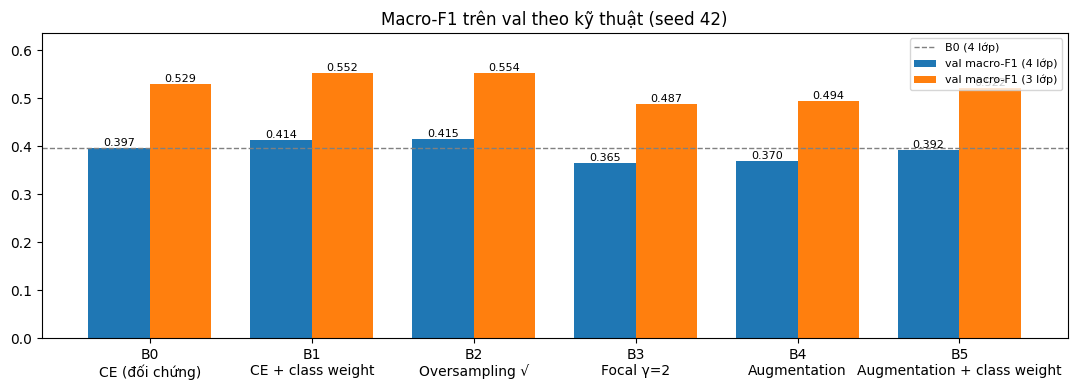

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(table))
for k, col in enumerate(["val macro-F1 (4 lớp)", "val macro-F1 (3 lớp)"]):
    bars = ax.bar(x + (k - 0.5) * 0.38, table[col], 0.38, label=col)
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
if "B0" in table.index:
    ax.axhline(table.loc["B0", "val macro-F1 (4 lớp)"], color="gray", linestyle="--", linewidth=1, label="B0 (4 lớp)")
ax.set_xticks(x, [f"{i}\n{d}" for i, d in zip(table.index, table["kỹ thuật"])])
ax.set_ylim(0, max(table["val macro-F1 (3 lớp)"]) * 1.15)
ax.set_title("Macro-F1 trên val theo kỹ thuật (seed 42)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Từng lớp

Lớp hiếm cần đọc kèm số mẫu: val có 28 `image-sarcasm` (1 mẫu ≈ 0,036 recall) và 1 `text-sarcasm` (F1 chỉ là 0 hoặc gần 1). Kỹ thuật tốt cho lớp hiếm thường đổi lại recall `not-sarcasm`.

precision                                               recall  \
lớp not-sarcasm text-sarcasm image-sarcasm multi-sarcasm not-sarcasm   
ID                                                                     
B0       0.5541          0.0        0.1786        0.8474      0.7421   
B1       0.7195          0.0        0.1304        0.8113      0.5747   
B2       0.5942          0.0        0.2222        0.8366      0.6923   
B3       0.7181          0.0        0.0000        0.7881      0.5475   
B4       0.5912          0.0        0.0000        0.8634      0.7919   
B5       0.5917          0.0        0.1094        0.8296      0.6787   

                                                      f1               \
lớp text-sarcasm image-sarcasm multi-sarcasm not-sarcasm text-sarcasm   
ID                                                                      
B0           0.0        0.1786        0.7134      0.6344          0.0   
B1           0.0        0.3214        0.8535      0.6390          0.0   
B2           0.0        0.2143        0.7718      0.6395          0.0   
B3           0.0        0.0000        0.9002      0.6213          0.0   
B4           0.0        0.0000        0.7516      0.6770          0.0   
B5           0.0        0.2500        0.7389      0.6322          0.0   

                                 
lớp image-sarcasm multi-sarcasm  
ID                               
B0         0.1786        0.7746  
B1         0.1856        0.8319  
B2         0.2182        0.8029  
B3         0.0000        0.8404  
B4         0.0000        0.8036  
B5         0.1522        0.7816

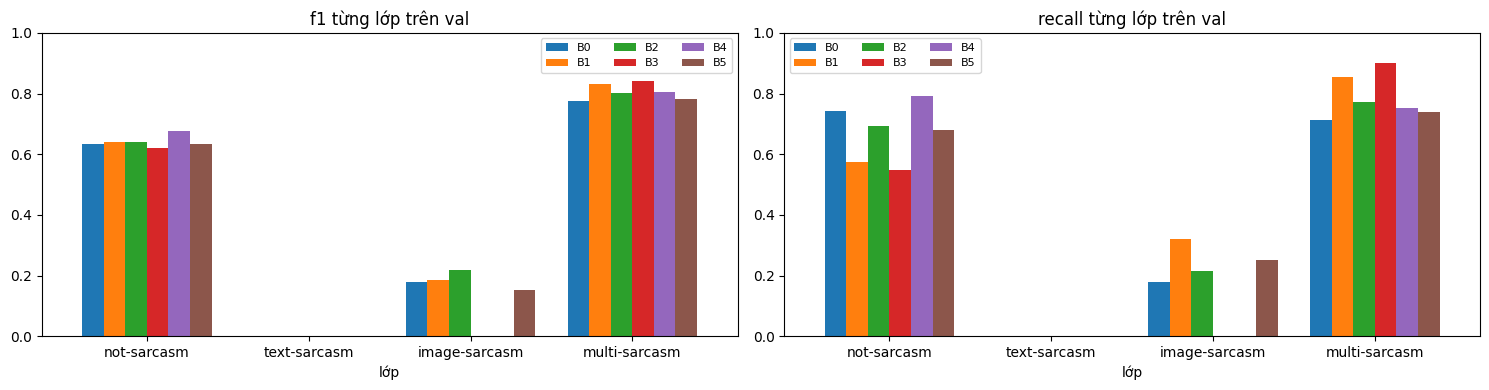

In [13]:
display(per_class.pivot(index="ID", columns="lớp", values=["precision", "recall", "f1"]).reindex(columns=LABELS, level=1).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, metric in zip(axes, ("f1", "recall")):
    pv = per_class.pivot(index="lớp", columns="ID", values=metric).reindex(LABELS)
    pv.plot.bar(ax=ax, rot=0, width=0.8)
    ax.set_title(f"{metric} từng lớp trên val"); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

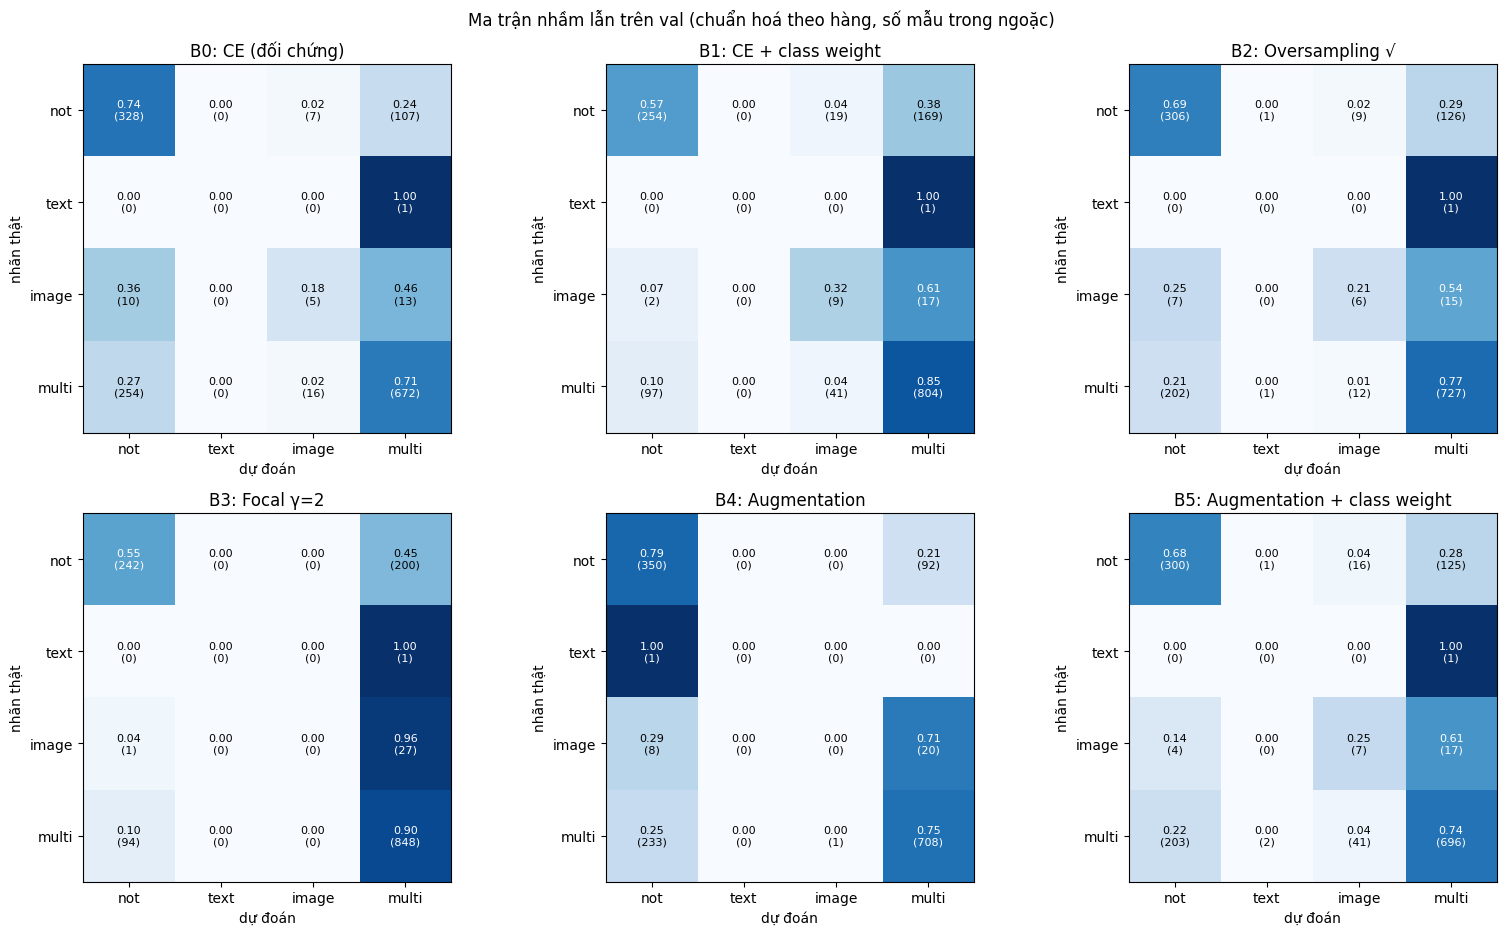

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
short = ["not", "text", "image", "multi"]
for ax, (mid, cm) in zip(axes.flat, cms.items()):
    norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xticks(range(4), short); ax.set_yticks(range(4), short)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("nhãn thật")
    ax.set_title(f"{mid}: {METHODS[mid][1]}")
for ax in list(axes.flat)[len(cms):]:
    ax.axis("off")
fig.suptitle("Ma trận nhầm lẫn trên val (chuẩn hoá theo hàng, số mẫu trong ngoặc)")
plt.tight_layout(); plt.show()

## 7. Diễn biến train và số lượt rút thực tế

Đường cong: train loss của focal và CE không cùng thang nên chỉ so hình dạng. `sampling.json` (run mới) xác nhận mọi run rút cùng 10.805 mẫu mỗi epoch và cho biết lớp hiếm được rút bao nhiêu lần.

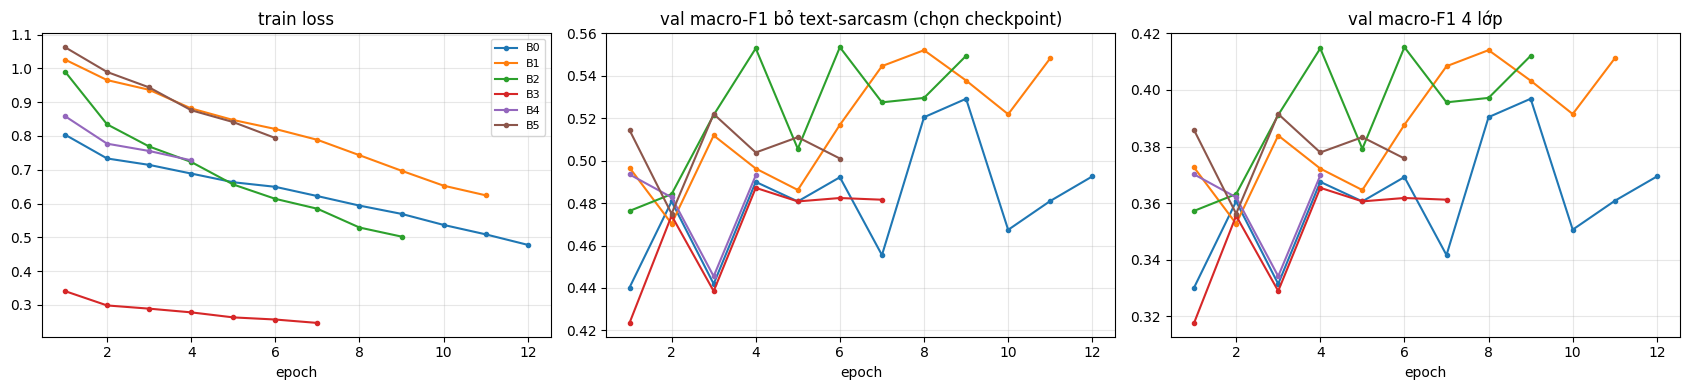

,rút / epoch,kích thước train,not-sarcasm (rút),text-sarcasm (rút),image-sarcasm (rút),multi-sarcasm (rút),text-sarcasm (bản aug),image-sarcasm (bản aug)
B2,10805.0,10805.0,4873.0,549.0,1316.0,4067.0,NaN,NaN
B4,10805.0,11131.0,5884.0,120.0,700.0,4100.0,47.0,279.0
B5,10805.0,11131.0,5884.0,120.0,700.0,4100.0,47.0,279.0


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for mid, h in histories.items():
    for ax, col in zip(axes, ("train loss", "val chọn ckpt", "val macro-F1")):
        ax.plot(h["epoch"], h[col], marker="o", markersize=3, label=mid)
for ax, title in zip(axes, ("train loss", "val macro-F1 bỏ text-sarcasm (chọn checkpoint)", "val macro-F1 4 lớp")):
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

sampling = {}
for mid, (group, _) in METHODS.items():
    s = read_json(OUT / f"{group}_s42" / "sampling.json")
    if s:
        sampling[mid] = {"rút / epoch": s["draws_per_epoch"], "kích thước train": s["dataset_size"],
                         **{f"{c} (rút)": round(v["draws_per_epoch"]) for c, v in s["classes"].items()},
                         **{f"{c} (bản aug)": v["augmented"] for c, v in s["classes"].items() if v["augmented"]}}
display(pd.DataFrame(sampling).T)

## 8. Dòng kết quả cho `reports/results.md` và doc Phase 9

In [16]:
for mid, (group, _) in METHODS.items():
    path = OUT / f"{group}_s42" / "results_row.md"
    if path.exists():
        print(path.read_text(encoding="utf-8").strip().splitlines()[-1])
cols = ["kỹ thuật", *SCORES, "Δ vs B0", "phút"]
print("\n| ID | " + " | ".join(cols) + " |\n|" + "---|" * (len(cols) + 1))
for mid, r in table[cols].iterrows():
    print(f"| {mid} | " + " | ".join(v if isinstance(v, str) else f"{v:.4f}" for v in r) + " |")

| 2026-11-13 | `emp_c_ce_s42` | `7a04f25` | kaggle | 0.3969 | nan | 30.0 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |
| 2026-11-13 | `emp_c_cw_s42` | `7a04f25` | kaggle | 0.4141 | nan | 26.9 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |
| 2026-11-14 | `emp_c_oversample_s42` | `1e86ff3` | kaggle | 0.4151 | nan | 21.6 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |
| 2026-11-13 | `emp_c_focal_s42` | `7a04f25` | kaggle | 0.3654 | nan | 9.9 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |
| 2026-11-14 | `emp_c_aug_s42` | `1e86ff3` | kaggle | 0.3702 | nan | 11.9 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |
| 2026-11-14 | `emp_c_aug_cw_s42` | `1e86ff3` | kaggle | 0.3915 | nan | 10.8 | plan empirical_imbalance_screen | peak VRAM 1.25 GB |

| ID | kỹ thuật | val macro-F1 (4 lớp) | val macro-F1 (3 lớp) | val weighted-F1 | val accuracy | Δ vs B0 | phút |
|---|---|---|---|---|---|---|---|
| B0 | CE (đối chứng) | 0.3969 | 0.5292 | 0.7184 | 0.7113 | 0.

## Đọc kết quả (nghiệm thu 9.3, 9.4)

1. **Bảng tổng hợp:** xếp hạng theo **val macro-F1 4 lớp**, kèm 3 lớp. B2, B4, B5 có vượt **B1** (ứng viên hiện tại) không, và vượt bao nhiêu. Mục tiêu thực tế trong plan là +1 điểm phần trăm macro-F1; chênh dưới mức đó với 1 seed chưa đủ để kết luận.
2. **Từng lớp:** recall `image-sarcasm` tăng thì recall `not-sarcasm` thường giảm. Nếu macro-F1 không tăng mà chỉ lớp hiếm tăng, ghi là đánh đổi, không gọi là cải thiện.
3. **Bẫy weighted-F1:** như B3, weighted-F1 cao không có nghĩa kỹ thuật tốt.
4. **Augmentation:** đọc kèm bảng lọc ở mục 3. Kết quả B4/B5 chỉ đáng tin bằng chất lượng bản sinh; nếu chưa duyệt tay, ghi rõ trong doc là chỉ lọc tự động.
5. **B4 so với B5:** tách được tác dụng của augmentation khi đã có class weight.
6. **Bước tiếp (plan mục 8.4):** chọn tối đa 1 kỹ thuật mới tốt nhất trong B2–B5; nếu không vượt B1 thì giữ B1. Chạy lại CE, B1 và kỹ thuật được chọn với seed 1/2/42 rồi mới chấm private test một lần.